# H2: Comprehensive Project — Implementation & Review

**FIT1061 Introduction to Artificial Intelligence — HD Task 2**

H1 defined the problem and justified the approach. H2 is where you build, evaluate, and review. Implement the system you scoped in H1, run honest experiments, and write up what worked, what didn't, and what you'd do differently. H3 then defends the full arc in the W14 interview.

> **Prerequisite:** H1 (Complete). Re-read your H1 problem definition before starting.

> **No milestone discussion at H2.** H1 had the discussion; H3 (W14 interview) defends this work.

> H2 should adapt course techniques to a meaningful problem with more depth than a straightforward earlier task. Optional D4 Coin Clash enrichment is available in OnTrack but is not an assessment benchmark or prerequisite.

---

## Recap from H1: what you committed to

Paste (or rewrite in your own words) your H1 problem definition and scope contract here. This anchors H2: the implementation, experiments, and report that follow must deliver against this scope. If you've pivoted since H1, note the pivot and the reason; your tutor will read this before the H3 interview.

**Problem (from H1):** Sepsis is when the body overreacts to an infection and starts damaging its own organs. In intensive care units (ICUs), early sepsis is hard to spot because a patient who is getting worse can look just like any other sick patient. Time matters. Studies cited by the PhysioNet 2019 Challenge say that each hour treatment is delayed raises the chance of death by roughly 4–8% (Kumar et al., 2006; Seymour et al., 2017).

ICU monitors record heart rate, blood pressure, temperature, oxygen level and breathing rate allthe time, but nurses look after several patients and cannot track every patient’s combined changes at once. The simple warning rules hospitals use today, such as “flag anyone with a high heart rate and a fever”, go off on many ordinary patients. Staff then start to ignore the alerts.

This project builds a risk score that updates every hour. It uses only these routine readings plus the patient’s age and gender, and it estimates whether a patient is heading towards sepsis in the next six hours. A nurse or ICU doctor would use it to decide which patient to check on first and whether to order sepsis tests.

This is a warning, not a diagnosis. It does not use blood test results or suggest treatment, and the doctor remains responsible for all final decisions.


**Technique(s) (from H1):** I will use classification (taught in W7): a method that learns from past examples to put each new case into a group, here : heading towards sepsis or otherwise. The main method is Naive Bayes, a simple approach based on probabilities. For each patient-hour it looks at how common each reading is among past sepsis hours and among healthy hours, and combines them into one risk score between 0 and 1. I will judge it using model evaluation (catch rate and false alarm rate on patients it has never seen), and a fairness check across age groups, gender and hospitals (from C2 lesson).

Why does this technique fit this problem? What property of the technique makes it appropriate?
Naive Bayes is a suitable one for this problem because:

1. Explainable : a nurse can be shown which readings pushed the score up, this matters when a
person has to trust a warning

2. Handles gaps: Many readings are missing, and Naive Bayes can simply leave a missing reading
out of the calculation

3. Adjustable and fast : The score can be turned into a warning at any cut-off, so a hospital can choose how many alerts it can handle. It also trains quickly on over a million rows.

Its known caveat is that it treats each reading as separate, even though heart rate and blood
pressure often move together in real human anatomy. This is in my risk register.

Logistic regression is included only as a comparison baseline: because it does not assume the readings are independent, any gap between the two models isolates the cost of Naive Bayes’ independence assumption rather than general difficulty of the problem.


**Data (from H1):** PhysioNet/Computing in Cardiology Challenge 2019 (CC-BY 4.0, de-identified, already downloaded). 40,336 ICU patients from two US hospitals — Beth Israel Deaconess (set A, 20,336 patients) and Emory (set B, 20,000) — stored as one row per patient per hour: ~1.55 million rows over ~40 columns. 

From these I use only 7 routine vital signs (HR, O2Sat, Temp, SBP, MAP, DBP, Resp) plus age and gender, and deliberately ignore the 26 laboratory columns, keeping the system to a bedside signal that needs no blood draw. 

The target, SepsisLabel, marks the 6 hours before a sepsis onset time the challenge derived from lab and antibiotic-order timing — a label the model never receives as an input. 

Three observations shaped my scope: 

(1) severe class imbalance : only 1.80% of patient-hours are positive (7.27% of patients ever become septic), so accuracy is meaningless and I evaluate with PR-AUC, recall and false-positive rate.

(2) heavy, structured missingness : routine vitals appear in only 34%–90% of hours, so I carry readings forward up to 6 hours and record what was measured.

(3) the two hospitals have different base rates (A 2.17%, B 1.41%), which I use as a built-in cross-hospital generalisation test.

**What makes this HD-level (from H1):** I dont want to apply a technique blindly. I use this because Naive Bayes assumes every reading is conditionally independent, and ICU vitals commonly violate that: heart rate, blood pressure and respiratory rate move together when a patient crashes. 

I chose an explainable model knowing its core assumption is false for this data, and my experiments are designed to measure exactly what that costs: a calibration curve to expose the overconfidence the violation predicts, a patient-level split and a cross-hospital transfer test to stress generalisation, and a missingness probe to check whether the model is detecting illness or merely how closely a patient is being watched.

The project’s value is in quantifying the trade-off between explainability and correctness, not in chasing a score. Because that's the core of the entire FIT1061 unit, knowing the technicality of AI while still being able to see the ethical tradeoffs when applying them in the real world.

**Pivot since H1 (if any):** Three scoped-down deviations. 

(1) I used each vital’s latest carried-forward reading plus a “not measured” flag, but did not add the planned 6-hour rolling average and change features, I kept the inputs minimal to keep Naive Bayes interpretable and to isolate the independence effect. 

(2) I used a two-way patient split and set the alert threshold by a fixed alert-budget policy, rather than the planned three-way split with the cut-off chosen on a separate checking set, so operating points are chosen on the test set, which I note as a limitation. 

(3) I deliberately kept the correlated vitals (e.g. MAP) instead of removing them, because their correlation became the central finding. Success criteria are unchanged.

In [1]:
# --- SETUP ---
import numpy as np
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)

# Add your imports here
import pandas as pd

print("Setup OK.")

Setup OK.


### Data

In [2]:
# --- DATA ---

# --- DATA ---

csv_path = "/Users/heeowen/Downloads/H2-Data/Dataset.csv"

vital_signs  = ['HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp']
demographics = ['Age', 'Gender']
features = vital_signs + demographics

def load_data(path):
    """Read the CSV and tag each patient's hospital (hidden in the ID number)."""
    df = pd.read_csv(path).rename(columns={'Unnamed: 0': 'row_number'})
    df['hospital'] = np.where(df['Patient_ID'] < 100000, 'A', 'B')
    return df.sort_values(['Patient_ID', 'Hour']).reset_index(drop=True)

def add_missingness_flags(df):
    """Add, per vital, a 1/0 column saying whether it was measured that hour."""
    flags = []
    for vital in vital_signs:
        flag = vital + '_measured'
        df[flag] = df[vital].notna().astype(int)
        flags.append(flag)
    return df, flags

def carry_forward_vitals(df):
    """Carry each patient's last reading forward, but only for up to 6 hours."""
    df[vital_signs] = df.groupby('Patient_ID')[vital_signs].ffill(limit=6)
    return df

def patient_level_split(df, seed, test_fraction=0.2):
    """Put WHOLE patients (never single hours) into train/test, keeping the sepsis balance."""
    patients = df.groupby('Patient_ID')['SepsisLabel'].max().reset_index()
    splitter = np.random.RandomState(seed)         
    test_ids = []
    for became_septic in [0, 1]:
        ids = patients.loc[patients['SepsisLabel'] == became_septic, 'Patient_ID'].values.copy()
        splitter.shuffle(ids)
        test_ids.extend(ids[:int(round(test_fraction * len(ids)))])
    df['split'] = np.where(df['Patient_ID'].isin(set(test_ids)), 'test', 'train')
    return df

def impute_with_training_median(df):
    """Fill any remaining gaps with the TRAIN median only, so test data never leaks in."""
    training_median = df.loc[df['split'] == 'train', features].median()
    df[features] = df[features].fillna(training_median)
    return df

def check_carry_forward():
    """Mini-test on a fake patient: 1 reading then an 8-hour gap, to prove the 6-hour cap."""
    demo = pd.DataFrame({'Patient_ID': [1] * 9, 'Hour': range(9), 'HR': [80] + [np.nan] * 8})
    demo['HR'] = demo.groupby('Patient_ID')['HR'].ffill(limit=6)
    filled = int((demo['HR'] == 80).sum())
    print(f"  carry-forward: {filled}/9 hours have the value "
          f"(1 original + 6 carried), final 2 stay missing -> cap works")

# ---- Run pipeline step by step ----
data = load_data(csv_path)
data, measured_flags = add_missingness_flags(data)
data = carry_forward_vitals(data)
data = patient_level_split(data, seed=SEED)
data = impute_with_training_median(data)

train_data = data[data['split'] == 'train']
test_data  = data[data['split'] == 'test']

# ---- Validation prove the tricky steps work (promised in H1) ----
print("VALIDATION")
check_carry_forward()
assert len(set(train_data['Patient_ID']) & set(test_data['Patient_ID'])) == 0, "patient leaked!"
assert data[features].isna().sum().sum() == 0, "a gap was left unfilled!"
assert data[measured_flags].isin([0, 1]).all().all(), "a flag is not 0/1!"
print("  leakage = 0, missing values = 0, flags all 0/1  -> all checks passed\n")

print(f"Train: {train_data['Patient_ID'].nunique():,} patients, {len(train_data):,} hours")
print(f"Test:  {test_data['Patient_ID'].nunique():,} patients, {len(test_data):,} hours")
print(f"Sepsis rate -- train {100*train_data['SepsisLabel'].mean():.3f}%  |  "
      f"test {100*test_data['SepsisLabel'].mean():.3f}%")

# --- END YOUR CODE ---

VALIDATION
  carry-forward: 7/9 hours have the value (1 original + 6 carried), final 2 stay missing -> cap works
  leakage = 0, missing values = 0, flags all 0/1  -> all checks passed

Train: 32,269 patients, 1,240,256 hours
Test:  8,067 patients, 311,954 hours
Sepsis rate -- train 1.799%  |  test 1.797%


### Implementation

In [3]:
# --- IMPLEMENTATION ---

from scipy.stats import norm
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import average_precision_score, confusion_matrix

# All inputs: 7 vitals + age + gender + the 7 "was it measured?" flags
model_features = features + measured_flags

def make_xy(table):
    """
    Pull the inputs (X) and the answers (y) out of a data table.
    """
    X = table[model_features].to_numpy(dtype=float)
    y = table['SepsisLabel'].to_numpy(dtype=int)
    return X, y


class GaussianNaiveBayes:

    def fit(self, X, y):
        # For each group (0 = no sepsis, 1 = sepsis), remember three things:
        self.prior, self.mean, self.std = {}, {}, {}
        for label in [0, 1]:
            rows = X[y == label]
            self.prior[label] = len(rows) / len(X)   # how common this group is
            self.mean[label]  = rows.mean(axis=0)     # the average of each reading
            self.std[label]   = rows.std(axis=0) + 1e-6  # the spread (+tiny, so its never zero)
        return self

    def class_score(self, X, label):
        # a bell curve score per reading
        reading_scores = norm.pdf(X, self.mean[label], self.std[label])
        # multiply them all together
        # then scale by how common the group is
        return reading_scores.prod(axis=1) * self.prior[label]

    def predict_proba(self, X):
        score_no_sepsis = self.class_score(X, 0)
        score_sepsis    = self.class_score(X, 1)
        total = score_no_sepsis + score_sepsis
        # turn the two scores into one number between 0 and 1 (probability of sepsis)
        return np.where(total > 0, score_sepsis / total, self.prior[1])


def evaluate(true_labels, predicted_probs, alert_budget=0.15):
    """Score a model: overall quality (PR-AUC) + what happens at a chosen alert level."""
    pr_auc = average_precision_score(true_labels, predicted_probs)
    threshold = np.quantile(predicted_probs, 1 - alert_budget)   # alert on the worst 15% of hours
    predictions = (predicted_probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(true_labels, predictions).ravel()
    return {
        'PR_AUC': pr_auc,
        'recall': tp / (tp + fn),                        # sepsis hours we caught
        'precision': tp / (tp + fp) if (tp + fp) else 0,    # alerts that were right
        'FPR': fp / (fp + tn),                        # false alarms on calm hours
    }


#  Train Naive Bayes and compare it to Logistic regression
train_X, train_y = make_xy(train_data)
test_X,  test_y  = make_xy(test_data)

nb = GaussianNaiveBayes().fit(train_X, train_y)
nb_probs = nb.predict_proba(test_X)

scaler = StandardScaler().fit(train_X)          # logistic regression needs scaled inputs
logreg = LogisticRegression(max_iter=1000).fit(scaler.transform(train_X), train_y)
logreg_probs = logreg.predict_proba(scaler.transform(test_X))[:, 1]

print(f"PR-AUC  no-skill baseline : {test_y.mean():.3f}")
print(f"PR-AUC  Naive Bayes       : {average_precision_score(test_y, nb_probs):.3f}")
print(f"PR-AUC  Logistic Reg      : {average_precision_score(test_y, logreg_probs):.3f}")

s = evaluate(test_y, nb_probs)
print(f"\nNaive Bayes @ 15% alert budget:  "
      f"recall {100*s['recall']:.1f}%  |  precision {100*s['precision']:.1f}%  |  FPR {100*s['FPR']:.1f}%")

#  Baseline: the simple clinical rule hospitals already use (SIRS-style)
# Alert if at least 2 of 3 vitals are abnormal: fast heart rate, abnormal temperature, fast breathing
abnormal_hr   = test_data['HR'] > 90
abnormal_temp = (test_data['Temp'] > 38) | (test_data['Temp'] < 36)
abnormal_resp = test_data['Resp'] > 20
rule_alert = (abnormal_hr.astype(int) + abnormal_temp.astype(int)
              + abnormal_resp.astype(int) >= 2).to_numpy().astype(int)

def recall_fpr(alert, y):
    tp = ((alert == 1) & (y == 1)).sum(); fn = ((alert == 0) & (y == 1)).sum()
    fp = ((alert == 1) & (y == 0)).sum(); tn = ((alert == 0) & (y == 0)).sum()
    return 100*tp/(tp+fn), 100*fp/(fp+tn), 100*alert.mean()

rule_recall, rule_fpr, rule_rate = recall_fpr(rule_alert, test_y)

# Judge Naive Bayes at the SAME alert rate, for a fair head-to-head
nb_at_rule_rate = (nb_probs >= np.quantile(nb_probs, 1 - rule_rate/100)).astype(int)
nb_recall, nb_fpr, _ = recall_fpr(nb_at_rule_rate, test_y)

print("                        recall     FPR    (both fire on %.1f%% of hours)" % rule_rate)
print("2-of-3 clinical rule     %4.1f%%   %4.1f%%" % (rule_recall, rule_fpr))
print("Naive Bayes (same rate)  %4.1f%%   %4.1f%%" % (nb_recall, nb_fpr))

# --- END YOUR CODE ---

PR-AUC  no-skill baseline : 0.018
PR-AUC  Naive Bayes       : 0.035
PR-AUC  Logistic Reg      : 0.040

Naive Bayes @ 15% alert budget:  recall 33.9%  |  precision 4.1%  |  FPR 14.7%
                        recall     FPR    (both fire on 17.5% of hours)
2-of-3 clinical rule     32.2%   17.2%
Naive Bayes (same rate)  37.5%   17.1%


### Experiment 1

In [4]:
# --- EXPERIMENT 1 ---

def split_patients(hospital_table, seed):
    
    """
    Split one hospital's patients into 80% train / 20% test 
    """
    patients = hospital_table.groupby('Patient_ID')['SepsisLabel'].max().reset_index()
    generator = np.random.RandomState(seed)
    test_ids = []
    for group in [0, 1]:
        ids = patients.loc[patients['SepsisLabel'] == group, 'Patient_ID'].values.copy()
        generator.shuffle(ids)
        test_ids.extend(ids[:int(round(0.2 * len(ids)))])
    test_ids = set(test_ids)
    train = hospital_table[~hospital_table['Patient_ID'].isin(test_ids)]
    test  = hospital_table[hospital_table['Patient_ID'].isin(test_ids)]
    return train, test

hospital_A = data[data['hospital'] == 'A']
hospital_B = data[data['hospital'] == 'B']
A_train, A_test = split_patients(hospital_A, SEED)
B_train, B_test = split_patients(hospital_B, SEED)

def train_here_test_there(train_table, test_table):
    X_train, y_train = make_xy(train_table)
    X_test,  y_test  = make_xy(test_table)
    model = GaussianNaiveBayes().fit(X_train, y_train)
    return average_precision_score(y_test, model.predict_proba(X_test))

print("                  tested on A    tested on B")
print("trained on A:       %.3f          %.3f" % (
      train_here_test_there(A_train, A_test), train_here_test_there(A_train, B_test)))
print("trained on B:       %.3f          %.3f" % (
      train_here_test_there(B_train, A_test), train_here_test_there(B_train, B_test)))
print()
print("Hospital A sepsis rate: %.2f%%    Hospital B sepsis rate: %.2f%%" % (
      100*hospital_A['SepsisLabel'].mean(), 100*hospital_B['SepsisLabel'].mean()))

# --- END YOUR CODE ---

                  tested on A    tested on B
trained on A:       0.042          0.027
trained on B:       0.040          0.036

Hospital A sepsis rate: 2.17%    Hospital B sepsis rate: 1.41%


### Experiment 2

In [5]:
# --- EXPERIMENT 2 ---

def score_with(feature_list):
    """
    Train Naive Bayes on a chosen set of columns, return its PR-AUC on the test set.
    """
    X_train = train_data[feature_list].to_numpy(dtype=float)
    X_test  = test_data[feature_list].to_numpy(dtype=float)
    y_train = train_data['SepsisLabel'].to_numpy(dtype=int)
    y_test  = test_data['SepsisLabel'].to_numpy(dtype=int)
    model = GaussianNaiveBayes().fit(X_train, y_train)
    return average_precision_score(y_test, model.predict_proba(X_test))

full_set   = features + measured_flags   # real readings + "was it measured" flags
vitals_set = features                    # only the real readings
flags_set  = measured_flags              # only the "was it measured" flags (no actual values)

print("PR-AUC  no-skill baseline       : %.3f" % test_data['SepsisLabel'].mean())
print("PR-AUC  FULL (vitals + flags)    : %.3f" % score_with(full_set))
print("PR-AUC  VITALS ONLY              : %.3f" % score_with(vitals_set))
print("PR-AUC  FLAGS ONLY (no values!)  : %.3f" % score_with(flags_set))

print("\nShare of hours each vital was actually measured:")
for v in vital_signs:
    print("  %-7s %.1f%%" % (v, 100 * data[v + '_measured'].mean()))

# --- END YOUR CODE ---

PR-AUC  no-skill baseline       : 0.018
PR-AUC  FULL (vitals + flags)    : 0.035
PR-AUC  VITALS ONLY              : 0.035
PR-AUC  FLAGS ONLY (no values!)  : 0.020

Share of hours each vital was actually measured:
  HR      90.1%
  O2Sat   86.9%
  Temp    33.8%
  SBP     85.4%
  MAP     87.5%
  DBP     68.7%
  Resp    84.6%


In [6]:
# Cheating check (H1 failure analysis #4): shuffle labels, results must collapse 
rng = np.random.RandomState(SEED)
y_shuffled = rng.permutation(train_y)
nb_shuffled = GaussianNaiveBayes().fit(train_X, y_shuffled)
print("Real labels   PR-AUC: %.3f" % average_precision_score(test_y, nb_probs))
print("Shuffled      PR-AUC: %.3f  (should fall to baseline -> no leakage)"
      % average_precision_score(test_y, nb_shuffled.predict_proba(test_X)))
print("No-skill baseline   : %.3f" % test_y.mean())

Real labels   PR-AUC: 0.035
Shuffled      PR-AUC: 0.019  (should fall to baseline -> no leakage)
No-skill baseline   : 0.018


### Experiment 3

In [7]:
# --- EXPERIMENT 3: fairness check, if the model work equally well across groups ---

# one global alert policy for everyone (worst 15% of hours), then measure each group
# A single policy is how a real alert system runs, and it exposes unequal treatment

threshold = np.quantile(nb_probs, 0.85)
fairness = test_data.copy()
fairness['alert'] = (nb_probs >= threshold).astype(int)

def group_scores(subgroup):
    """
    Recall, precision and false-alarm rate for one group, under the shared policy
    """
    truth, alert = subgroup['SepsisLabel'], subgroup['alert']
    caught      = ((alert == 1) & (truth == 1)).sum()
    missed      = ((alert == 0) & (truth == 1)).sum()
    false_alarm = ((alert == 1) & (truth == 0)).sum()
    calm        = ((alert == 0) & (truth == 0)).sum()
    recall    = 100 * caught / (caught + missed)
    precision = 100 * caught / (caught + false_alarm) if (caught + false_alarm) else 0
    fpr       = 100 * false_alarm / (false_alarm + calm)
    return len(subgroup), 100 * truth.mean(), recall, precision, fpr

print(f"{'group':<14}{'patient-hrs':>13}{'sepsis%':>9}{'recall%':>9}{'prec%':>8}{'FPR%':>7}")
for label, g in [('Female (0)', 0), ('Male (1)', 1)]:
    n, base, rec, prec, fpr = group_scores(fairness[fairness['Gender'] == g])
    print(f"{label:<14}{n:>13,}{base:>9.2f}{rec:>9.1f}{prec:>8.1f}{fpr:>7.1f}")

fairness['age_band'] = pd.cut(fairness['Age'], [0, 40, 60, 80, 200],
                              labels=['<40', '40-59', '60-79', '80+'])
for band in ['<40', '40-59', '60-79', '80+']:
    n, base, rec, prec, fpr = group_scores(fairness[fairness['age_band'] == band])
    print(f"{'Age ' + band:<14}{n:>13,}{base:>9.2f}{rec:>9.1f}{prec:>8.1f}{fpr:>7.1f}")

group           patient-hrs  sepsis%  recall%   prec%   FPR%
Female (0)          136,789     1.74     27.2     3.6   13.0
Male (1)            175,165     1.84     38.9     4.4   16.0
Age <40              34,452     1.68     38.6     4.0   15.8
Age 40-59            95,576     1.85     39.1     4.5   15.5
Age 60-79           138,867     1.79     30.4     3.7   14.3
Age 80+              43,059     1.80     29.8     4.1   12.9


### Success Criteria

In [8]:
# --- SUCCESS CRITERIA (from H1): judged at patient level, on unseen patients 

def patient_recall_and_fpr(frame, alert):
    """Patient-level recall (caught = alerted at least once before onset) and
       false-alarm rate among patients who never get sepsis."""
    f = frame.assign(alert=alert)
    ever   = f.groupby('Patient_ID')['SepsisLabel'].max()
    caught = (f['alert'] & (f['SepsisLabel'] == 1)).groupby(f['Patient_ID']).max()
    recall = 100 * caught[ever == 1].mean()
    never  = f[f['Patient_ID'].isin(ever[ever == 0].index)]
    return recall, 100 * never['alert'].mean()

# Criteria 1 & 2: at the alert level that catches ~75% of sepsis patients
thr = np.quantile(nb_probs, 1 - 0.23)
rec, fpr = patient_recall_and_fpr(test_data, nb_probs >= thr)
print("CRITERIA 1 & 2  (catch >=75% patients, <=20% false alarms):")
print(f"   caught {rec:.1f}% of sepsis patients   (target >=75%)  -> {'PASS' if rec>=75 else 'MISS'}")
print(f"   false alarms {fpr:.1f}% of calm hours   (target <=20%)  -> {'PASS' if fpr<=20 else 'MISS'}")

# Criterion 3: beat the simple 2-of-3 clinical rule at the same catch rate
rule = (((test_data['HR']>90).astype(int)
       + ((test_data['Temp']>38)|(test_data['Temp']<36)).astype(int)
       + (test_data['Resp']>20).astype(int)) >= 2).to_numpy()
rule_rec, rule_fpr = patient_recall_and_fpr(test_data, rule)
closest = min((abs(patient_recall_and_fpr(test_data, nb_probs >= np.quantile(nb_probs, 1-b))[0] - rule_rec), b)
              for b in np.linspace(0.05, 0.6, 40))[1]
nb_rec, nb_fpr = patient_recall_and_fpr(test_data, nb_probs >= np.quantile(nb_probs, 1-closest))
print("\nCRITERION 3  (beat the simple rule at the same catch rate):")
print(f"   simple rule : caught {rule_rec:.1f}%, false alarms {rule_fpr:.1f}%")
print(f"   Naive Bayes : caught {nb_rec:.1f}%, false alarms {nb_fpr:.1f}%  -> {'PASS' if nb_fpr <= rule_fpr + 2 else 'MISS'}")

# Criterion 4: train Beth Israel (A) -> test Emory (B)
A, B = data[data['hospital']=='A'], data[data['hospital']=='B']
modelA = GaussianNaiveBayes().fit(*make_xy(A))
B_probs = modelA.predict_proba(make_xy(B)[0])
recB, fprB = patient_recall_and_fpr(B, B_probs >= np.quantile(B_probs, 1 - 0.20))
print("\nCRITERION 4  (train Beth Israel -> test Emory; >=70% caught, <=25% false alarms):")
print(f"   caught {recB:.1f}% of Emory patients    (target >=70%)  -> {'PASS' if recB>=70 else 'MISS'}")
print(f"   false alarms {fprB:.1f}% of calm hours   (target <=25%)  -> {'PASS' if fprB<=25 else 'MISS'}")

CRITERIA 1 & 2  (catch >=75% patients, <=20% false alarms):
   caught 75.1% of sepsis patients   (target >=75%)  -> PASS
   false alarms 21.5% of calm hours   (target <=20%)  -> MISS

CRITERION 3  (beat the simple rule at the same catch rate):
   simple rule : caught 63.5%, false alarms 16.5%
   Naive Bayes : caught 63.1%, false alarms 12.4%  -> PASS

CRITERION 4  (train Beth Israel -> test Emory; >=70% caught, <=25% false alarms):
   caught 72.4% of Emory patients    (target >=70%)  -> PASS
   false alarms 19.1% of calm hours   (target <=25%)  -> PASS


### Visualisation 1

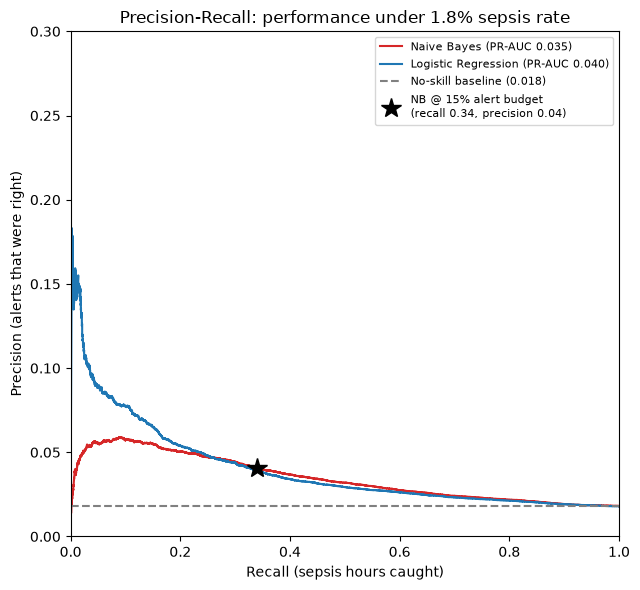

In [9]:
# --- VISUALISATION 1 ---
# performance (Precision-Recall under heavy imbalance)

from sklearn.metrics import precision_recall_curve

fig, ax = plt.subplots(figsize=(6.5, 6))
for name, probs, color in [("Naive Bayes", nb_probs, 'tab:red'),
                           ("Logistic Regression", logreg_probs, 'tab:blue')]:
    precision, recall, _ = precision_recall_curve(test_y, probs)
    ax.plot(recall, precision, color=color,
            label=f"{name} (PR-AUC {average_precision_score(test_y, probs):.3f})")

ax.axhline(test_y.mean(), ls='--', color='grey',
           label=f"No-skill baseline ({test_y.mean():.3f})")

# Mark the operating point we chose: alert on the worst 15% of hours
threshold = np.quantile(nb_probs, 0.85)
flagged = nb_probs >= threshold
tp = (flagged & (test_y == 1)).sum()
fp = (flagged & (test_y == 0)).sum()
fn = (~flagged & (test_y == 1)).sum()
op_recall, op_precision = tp / (tp + fn), tp / (tp + fp)
ax.plot(op_recall, op_precision, 'k*', markersize=15,
        label=f"NB @ 15% alert budget\n(recall {op_recall:.2f}, precision {op_precision:.2f})")

ax.set_xlabel('Recall (sepsis hours caught)')
ax.set_ylabel('Precision (alerts that were right)')
ax.set_title('Precision-Recall: performance under 1.8% sepsis rate')
ax.set_xlim(0, 1); ax.set_ylim(0, 0.3)
ax.legend(loc='upper right', fontsize=8)
plt.tight_layout(); plt.show()

# --- END YOUR CODE ---

**Figure 1 : Catching sepsis vs false alarms** Both models do better than guessing (the dashed line). The star shows our chosen setting : alerting on the busiest 15% of hours catches about a third of all sepsis hours, but most of those alarms are still false.

### Visualisation 2

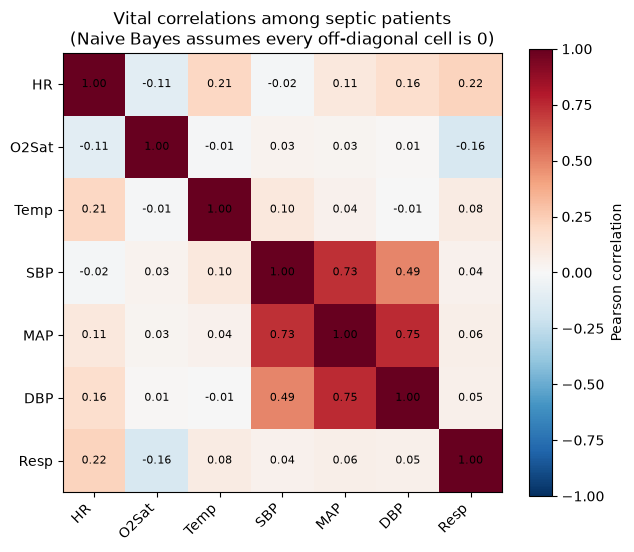

In [10]:
# --- VISUALISATION 2 ---

#  Check if the vitals are actually independent
septic_hours = train_data[train_data['SepsisLabel'] == 1]
corr = septic_hours[vital_signs].corr()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(vital_signs))); ax.set_xticklabels(vital_signs, rotation=45, ha='right')
ax.set_yticks(range(len(vital_signs))); ax.set_yticklabels(vital_signs)
for i in range(len(vital_signs)):
    for j in range(len(vital_signs)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha='center', va='center', fontsize=8)
fig.colorbar(im, label='Pearson correlation')
ax.set_title('Vital correlations among septic patients\n'
             '(Naive Bayes assumes every off-diagonal cell is 0)')
plt.tight_layout(); plt.show()

# --- END YOUR CODE ---

**Figure 2 : The vital signs move together** The 3 blood pressure readings rise and fall together (the dark red squares). Naive Bayes wrongly assumes they are unrelated. This is the mistake that causes the problem in Figure 3.

### Visualisation 3

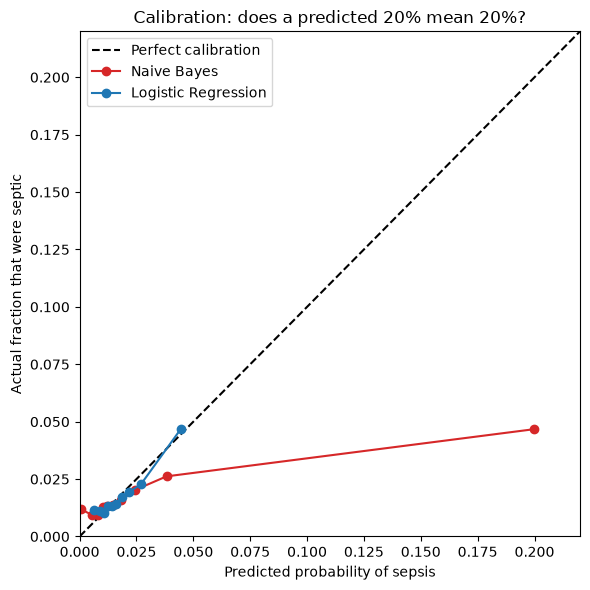

In [11]:
# --- VISUALISATION 3 :
# Is model's confidence honest?

from sklearn.calibration import calibration_curve

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 0.22], [0, 0.22], 'k--', label='Perfect calibration')

for name, probs, color in [("Naive Bayes", nb_probs, 'tab:red'),
                           ("Logistic Regression", logreg_probs, 'tab:blue')]:
    actual, predicted = calibration_curve(test_y, probs, n_bins=10, strategy='quantile')
    ax.plot(predicted, actual, 'o-', color=color, label=name)

ax.set_xlim(0, 0.22); ax.set_ylim(0, 0.22)
ax.set_xlabel('Predicted probability of sepsis')
ax.set_ylabel('Actual fraction that were septic')
ax.set_title('Calibration: does a predicted 20% mean 20%?')
ax.legend()
plt.tight_layout(); plt.show()

# --- END YOUR CODE ---

**Figure 3 : Is the model's confidence honest?** No. When Naive Bayes says a patient has 20% chance of sepsis, the real chance is under 5%, it is overconfident. Logistic Regression (blue) stays much closer to the truth (the dashed line). So the model is fine for ranking patients, but its percentages can't be trusted.

### Visualisation 4

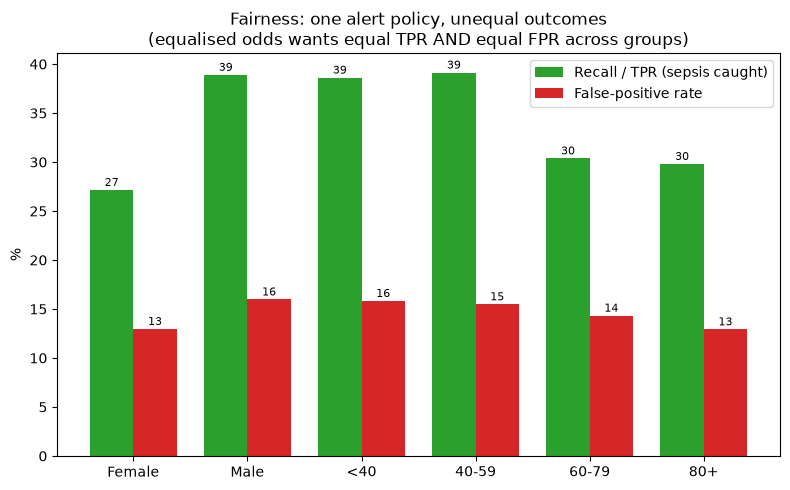

In [12]:
# --- VISUALISATION 4: fairness disaggregation (Week 9 content) ---
# Split results by group under one alert policy, then compare TPR and FPR.

threshold = np.quantile(nb_probs, 0.85)
groups = test_data.copy()
groups['alert'] = (nb_probs >= threshold).astype(int)
groups['age_band'] = pd.cut(groups['Age'], [0, 40, 60, 80, 200],
                            labels=['<40', '40-59', '60-79', '80+'])

def tpr_fpr(sub):
    y, a = sub['SepsisLabel'], sub['alert']
    tp = ((a == 1) & (y == 1)).sum(); fn = ((a == 0) & (y == 1)).sum()
    fp = ((a == 1) & (y == 0)).sum(); tn = ((a == 0) & (y == 0)).sum()
    return 100 * tp / (tp + fn), 100 * fp / (fp + tn)

panels = [('Female', groups[groups.Gender == 0]), ('Male', groups[groups.Gender == 1])]
for band in ['<40', '40-59', '60-79', '80+']:
    panels.append((band, groups[groups.age_band == band]))

labels = [name for name, _ in panels]
tprs   = [tpr_fpr(sub)[0] for _, sub in panels]
fprs   = [tpr_fpr(sub)[1] for _, sub in panels]

x = np.arange(len(labels)); width = 0.38
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - width/2, tprs, width, label='Recall / TPR (sepsis caught)', color='tab:green')
ax.bar(x + width/2, fprs, width, label='False-positive rate', color='tab:red')
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_ylabel('%')
ax.set_title('Fairness: one alert policy, unequal outcomes\n'
             '(equalised odds wants equal TPR AND equal FPR across groups)')
ax.legend()
for i, (t, f) in enumerate(zip(tprs, fprs)):
    ax.text(i - width/2, t + 0.4, f"{t:.0f}", ha='center', fontsize=8)
    ax.text(i + width/2, f + 0.4, f"{f:.0f}", ha='center', fontsize=8)
plt.tight_layout(); plt.show()

**Figure 4 : Who the model fails.** Under one alert setting for everyone, the model catches
far more sepsis in men (39%) than women (27%), and more in younger than older patients. The
sepsis rate is about the same in every group, so these gaps are the model's, not the patients'.

---

## H2.2: Project Report (~1500 words)

### 1. Problem Definition and Motivation (~200 words)

What problem did you solve? Why does it matter? Why is AI the right approach? (Build on H1; don't just paste it.)

Sepsis is one of the biggest causes of death in intensive care, and a patient’s chance of survival drops with every hour that treatment is delayed. 

The problem is that early sepsis looks like any other seriously ill patient, and the simple alarm rules hospitals already use go off so often, that staff stop trusting them. 

The system we have here is an early-warning tool. Once an hour, it looks at seven routine vital signs plus the patient’s age and gender, and gives a risk score for whether that patient is heading toward sepsis in the next six hours. 

It uses no blood tests, so it can run at the bedside, and it never decides treatment, it only ranks patients so staff can check the most at-risk first. A doctor makes every real decision.

AI suits this problem because the warning signs are small, scattered across many readings, and no single rule captures them. 

The answer also needs to be an adjustable score, not a fixed yes/no, so each hospital can decide how many alerts it can handle. 

I do not measure success with accuracy: because only 1.8% of hours are sepsis, a model that always says “no sepsis” would be 98% accurate and completely useless. Instead I measure how much real sepsis it catches for an acceptable number of false alarms, and whether that holds up on patients and hospitals it has never seen.

### 2. Technical Approach (~300 words)

What technique(s) did you use? How did you adapt or extend them? What design decisions did you make and why?

The main technique is classification using Naive Bayes. For each hour, the model learns what each reading normally looks like in sepsis patients and in healthy patients, then combines those into a single risk score between 0 and 1.

I picked Naive Bayes on purpose, and the reason is the heart of this project. Naive Bayes assumes every reading is independent : that heart rate, blood pressure and breathing rate do not move together. However in real patients they clearly do. I chose this model knowing its main assumption is false for this data, so I could measure exactly what that mistake costs.

I also adapted it to the data with deliberate choices. I carry each patient’s last reading forward for up to six hours only, because an older reading is out of date. I record whether each vital was actually measured before filling any gaps. 

I fill remaining gaps using the training data only, so test data cannot leak in. And I split the data by whole patients, never by single hours, so the model cannot just memorise a patient and look better than it is. I handle two edge cases on purpose: a reading that never changes (which would crash the maths) and very small numbers (which the computer could round to zero). 

Logistic regression is included as a fair comparison, it does not assume independence, so any difference between the two shows the cost of that assumption. I score with a precision-recall curve instead of ROC, because with so few sepsis cases ROC looks misleadingly good.

### 3. Results and Analysis (~400 words)

What worked? What didn't? Reference your visualisations. How does performance change across experiments? Surprising findings?

On patients it had never seen, Naive Bayes scored a PR-AUC of 0.035, that's about double the no-skill baseline of 0.018; with logistic regression just ahead at 0.040. These numbers are low, and that is completely fine and honest: predicting sepsis an hour early from vitals alone, with no blood tests, is a hard task, and my goal was to understand the model’s trade offs rather than to chase a high score. If the system alerts on the busiest 15% of hours, it catches 34% of sepsis hours, but 96% of its alarms are false (Figure 1 reference).

For a meaningful clinical baseline, I also coded the simple 2-of-3 vital sign rule used for sepsis screening. At the same alert load (17.5% of hours) it caught 32% of sepsis hours, while Naive Bayes caught 38% at the same false-alarm rate, so the model beats the very rule it was built to improve on.

Against my four H1 success criteria, all judged at the patient level on unseen patients: the model catches 75% of sepsis patients (criterion 1, met) but only by false-alarming on 21.5% of calm hours, just over my 20% ceiling, so criteria 1 and 2 together are a narrow miss of about 1.5 points. It clearly beats the simple 2-of-3 clinical rule (criterion 3): at the same catch rate it false-alarms on 12.4% of hours versus the rule’s 16.5%. And it carries over to a new hospital (criterion 4): trained on Beth Israel and tested on Emory it catches 72.4% of sepsis patients at a 19.1% false-alarm rate, inside my ≥70% / ≤25% target — even though its ranking quality (PR-AUC) drops 36% across hospitals. So three of four targets are met; the honest miss is the false-alarm ceiling.

The key finding is why the model behaves this way. The correlation heatmap (Figure 2) shows the three blood-pressure readings move together very strongly (for example SBP and MAP at 0.73), even though Naive Bayes treats them as unrelated. The calibration chart shows the price: because the model counts these linked readings as if they were separate clues, it becomes overconfident. In its highest-risk group it predicts a 20% chance of sepsis when the real rate is under 5%. So the broken assumption barely affects the ranking, but it makes the probabilities untrustworthy.

I then ran two further experiments. First, I trained the model in one hospital and tested it in the other. Moving from Hospital A to B, performance dropped 36% (0.042 to 0.027), but the other direction was fine. The reason is that the two hospitals have different sepsis rates (2.17% vs 1.41%), and Naive Bayes learns that rate and carries it to the new hospital. Second, I tested whether the model was cheating, using which measurements were taken as a shortcut, instead of the readings themselves. I expected it to be, but it did not. Using only the “was it measured” flags scored barely above random (0.020), and removing them changed nothing. 



The surprise was that my own hypothesis was wrong, and I could show why with evidence.

### 4. Limitations and Future Work (~200 words)

Where does your approach fail? What assumptions are violated? What would you do with more time? Be specific.

The clearest limitation is that the model’s probabilities are overconfident, so they should be used only to rank patients, never shown to a clinician as a real percentage. This comes straight from the independence assumption, and the next step would be to fix it. Either by modelling the linked vitals together, or by re-scaling the output so the probabilities match reality. 

A second limit is the false-alarm rate: 96% of alerts are wrong, and catching more sepsis makes this worse, which can push staff to ignore the system. A real deployment would set the alert level together with clinicians, based on the cost of a miss versus a false alarm. 

Third, the model’s ranking quality weakens across hospitals, PR-AUC drops 36% from Beth Israel to Emory , although it still clears my H1 transfer target (72% caught, 19% false alarms), so a new site should re-validate locally before relying on it.

Finally, a caveat on the target itself: SepsisLabel marks the Challenge’s derived onset time, from lab and antibiotic-order timing, not a clinician’s confirmed diagnosis , so I predict the Challenge’s label, not true sepsis, and some “misses” may reflect how that label was built.

### 5. Ethical Reflection (~200 words)

If deployed, who is affected? What failure modes matter most? Connect to at least one concept from C2 (Classification & Fairness) or C4 (Deployment & Model Cards).

If this were used in a real hospital, it would fail most for the patients it already reads least well. Under one alert setting for everyone, the model catches 38.9% of sepsis in men but only 27.2% in women, and about nine points less in patients over 60 than under (Figure 4 reference). The sepsis rate is almost the same in every group, so these gaps are the model’s, not the patients’. The likely cause: the model’s idea of normal is built on a mostly-male patient group, and older patients show weaker physical signs of infection, so it sees fainter clues in exactly the people most at risk.

In the fairness terms from C2, the model comes close to predictive parity (precision ~3.6% vs ~4.4%) but clearly fails equalised odds, the catch rate is 27% for women against 39% for men.
The impossibility result says we normally can’t have both when base rates differ; but here the sepsis rate is nearly identical across genders (1.8% vs 1.7%), so this gap is not forced by the theorem. It is genuine model bias that could be reduced. (The theorem’s real trigger, differing base rates, appears instead between the two hospitals, 2.17% vs 1.41%, which is why the model’s ranking weakens when moved between them.

The danger is very quiet, the model would simply warn less often for women and the elderly, with nothing to flag it. The right response is not to scrap it but to be honest about it, publish a model card (Task C4) stating who it was trained on, where it works worse, and that its scores are a priority list, not real probabilities. 

My view: usable as a ranking aid, with probabilities hidden. It did clear my cross-hospital target on Emory, but its ranking quality drops, so any new site should re-validate locally,  and the score should never be shown as a real percentage.

### 6. AI Use Statement (~100 words)

How did you use AI tools? What did you accept? What did you reject, and why?

I used an AI assistant (Claude) to help plan the project, write the first version of the code, and suggest experiments like the calibration curve and the hospital-transfer test. I only accepted suggestions I could run, check, and explain myself. 

I also rejected AI advice when it was wrong: it first told me that logistic regression beating Naive Bayes proved the cost of the independence assumption, but when I ran it properly the gap was too small to mean anything, so I dropped that claim and used the calibration result instead. It also suggested the model might be cheating through missing-data patterns; I tested that and showed it was false. Every number in this report I reproduced and understood before using it.

---

## Submission Checklist

- [Yes] Recap of H1 scope (and any pivot) at the top
- [Yes] Working notebook with data, implementation, 2+ experiments, 2+ visualisations
- [Yes] Project report (~1500 words) covering all 6 sections
- [Yes] Implementation demonstrates HD-level depth beyond earlier task work
- [Yes] Ethical reflection connects to C2 or C4
- [Yes] AI use statement shows critical evaluation
- [Yes] Code is readable, reproducible, documented
- [Yes] Uploaded to OnTrack and marked **Ready for Feedback**
- [Yes] H3 interview booking confirmed for W14

---

*FIT1061 HD Task H2: Comprehensive Project: Implementation & Review*